In [36]:
# importing the libraries
from cobaya import run, load_samples
from cobaya.yaml import yaml_load_file
import pathlib
from cobaya.samplers.mcmc import plot_progress
import matplotlib.pyplot as plt
from getdist.mcsamples import loadMCSamples, MCSamplesFromCobaya
import getdist.plots as gdplt
import scipy.stats as st
import numpy as np
import pandas as pd
import datetime

In [37]:

plt.rcParams.update({
#    "font.family": "sans-serif",
#    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 15,                   # Nature standard: 5–7 pt
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "xtick.labelsize": 12.5,
    "ytick.labelsize": 12.5,
    "legend.fontsize": 12.5,
#    "axes.linewidth": 0.5,
#    "lines.linewidth": 0.75,
#    "xtick.major.width": 0.5,
#    "ytick.major.width": 0.5,
#    "xtick.major.size": 3,
#    "ytick.major.size": 3,
#    "figure.dpi": 150,
#    "savefig.dpi": 450,               # Nature recommends 450 dpi+
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


In [38]:
path = "/home/aria-hemmatian/chains"

def give_sample_from_file(chain_path):
    gd_samples = []
    for single_path in chain_path:
        gd_samples.append(loadMCSamples(path+'/'+single_path, settings={'ignore_rows':0.3}))
    return gd_samples

# ploting the results
def tri_plot(gd_samples, gd_sample_names, params=['H0','omegam'], color=['blue'], filled = True, wid=9):
    gdplot = gdplt.get_subplot_plotter(width_inch=wid)
    gdplot.triangle_plot(gd_samples, params, legend_labels=gd_sample_names, contour_colors=color, filled=filled, title_limit=1)
    #gdplot.add_legend(gd_sample_names,bbox_to_anchor=(1.0,1.0))
    return gdplot

---
# CMB

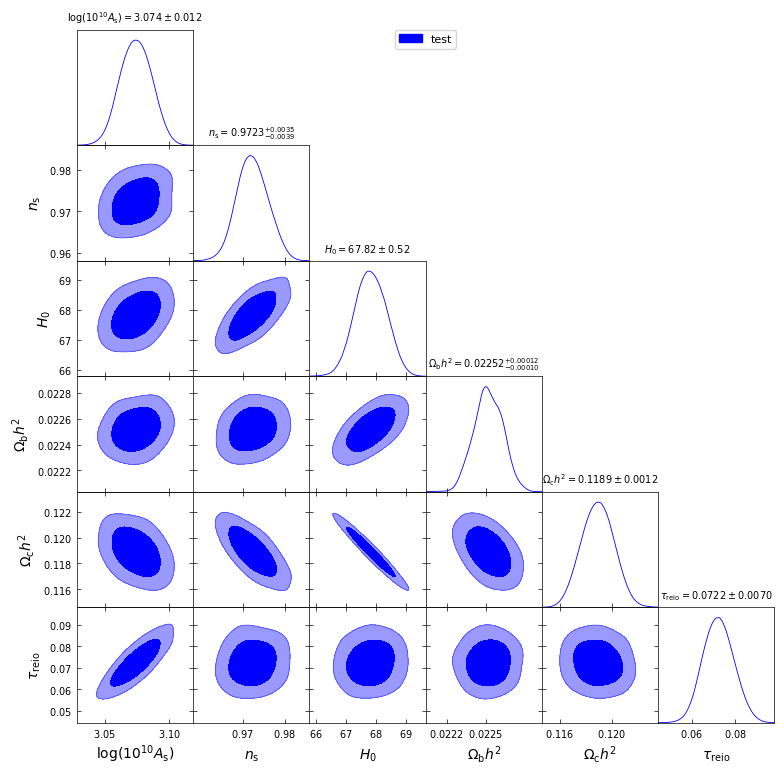

In [39]:
sample = give_sample_from_file(['CMB_0.07/chain'])
tri_plot(sample,['test'],params=['logA','ns','H0','ombh2','omch2','tau'])

---
# CPL CMB 

In [40]:
sample = give_sample_from_file(['mywtest_desi/chain'])
baseline = give_sample_from_file(['baseline/chain'])

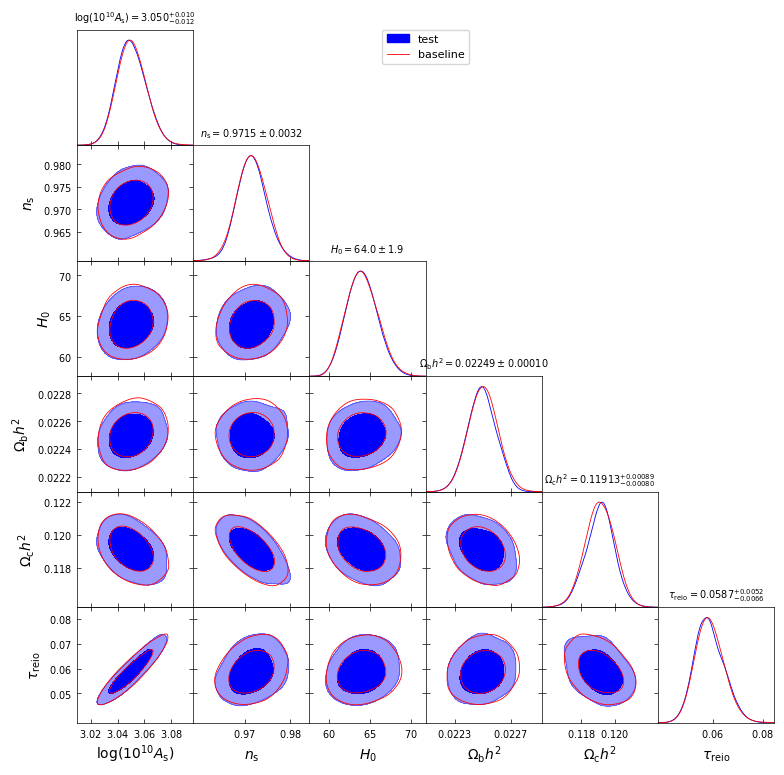

In [41]:
tri_plot(sample+baseline,['test','baseline'],params=['logA','ns','H0','ombh2','omch2','tau'],color=['blue','red'], filled = [True,False])

---
# CMB with $\tau \in \{0.05, 0.06, 0.07, 0.08, 0.09\}$

In [14]:
sample = give_sample_from_file(['CMB_0.05/chain','CMB_0.06/chain','CMB_0.07/chain','CMB_0.08/chain','CMB_0.09/chain'])
tri_plot(sample,
         [r'$\tau_\text{reio} = 0.05$',r'$\tau_\text{reio} = 0.06$',r'$\tau_\text{reio} = 0.07$',r'$\tau_\text{reio} = 0.08$',r'$\tau_\text{reio} = 0.09$'],
         params=['logA','ns','H0','ombh2','omch2','tau'],
         color=['red','orange','green','cyan','blue'],
         filled=[False,False,False,False,False])
plt.savefig('CMBalltau.pdf')

FileNotFoundError: [Errno 2] No such file or directory: '/home/aria-hemmatian/Desktop/test2/CMB_0.05'

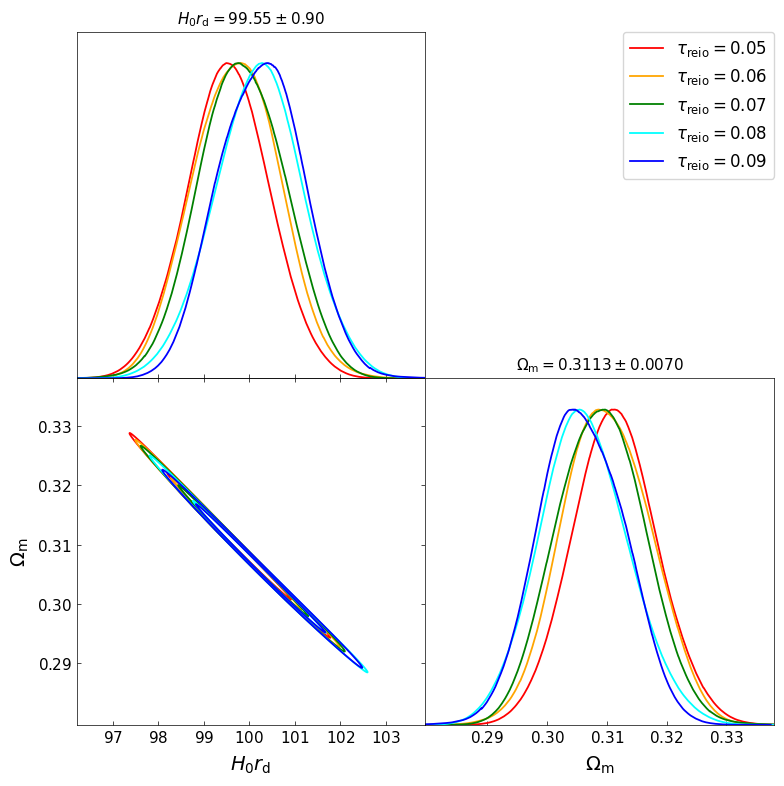

In [ ]:
sample = give_sample_from_file(['CMB_0.05/chain','CMB_0.06/chain','CMB_0.07/chain','CMB_0.08/chain','CMB_0.09/chain'])
tri_plot(sample,
         [r'$\tau_\text{reio} = 0.05$',r'$\tau_\text{reio} = 0.06$',r'$\tau_\text{reio} = 0.07$',r'$\tau_\text{reio} = 0.08$',r'$\tau_\text{reio} = 0.09$'],
         params=['H0rd','omegam'],
         color=['red','orange','green','cyan','blue'],
         filled=[False,False,False,False,False])
plt.savefig('CMBalltau-OmH0rd.pdf')

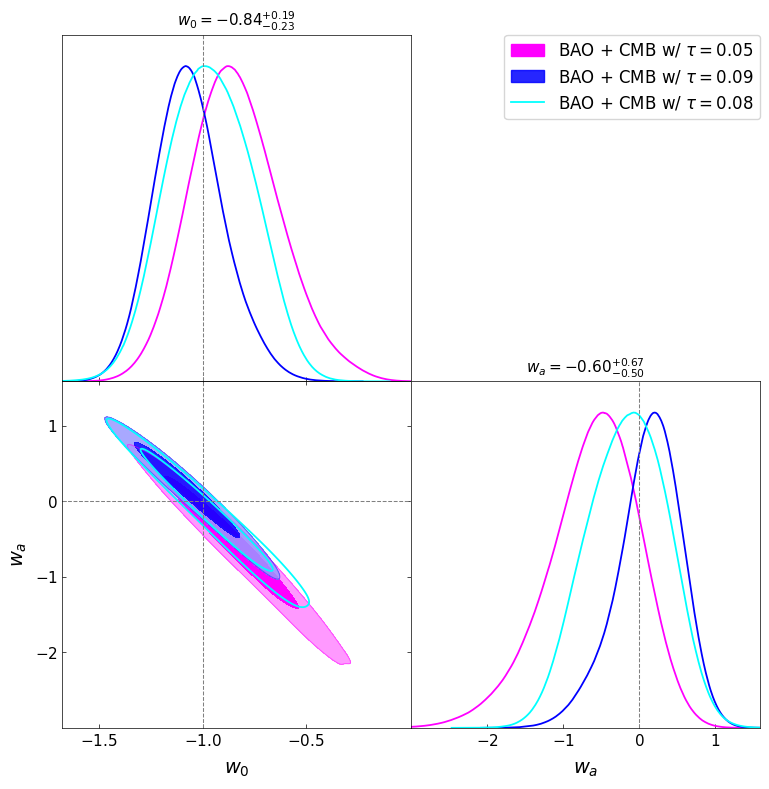

In [ ]:
sample = give_sample_from_file(['fakes/mcmc/fake_bao_w0wa_0.05_038/chain','fakes/mcmc/fake_bao_w0wa_0.09_038/chain','fakes/mcmc/fake_bao_w0wa_0.08_038/chain'])
gdplot = tri_plot(sample,[r'BAO + CMB w/ $\tau = 0.05$',r'BAO + CMB w/ $\tau = 0.09$',r'BAO + CMB w/ $\tau = 0.08$'],params=['w','wa'],filled=[True, True, False],color=['magenta','blue','cyan'])
for ax in gdplot.subplots[:, 0]:
    ax.axvline(x=-1, color='gray', linestyle='--')
for ax in gdplot.subplots[1]:
    ax.axhline(y=0, color='gray', linestyle='--')
    break
ax = gdplot.subplots[1,1]
ax.axvline(x=0, color='gray', linestyle='--')
plt.savefig('w0wa_tau.pdf')

---

In [ ]:
from cobaya import run
from cobaya.yaml import yaml_load_file
import matplotlib.pyplot as plt
from getdist.mcsamples import loadMCSamples, MCSamplesFromCobaya
import getdist.plots as gdplt

from cobifact import *

In [ ]:

plt.rcParams.update({
#    "font.family": "sans-serif",
#    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 20,                   # Nature standard: 5–7 pt
    "axes.labelsize": 30,
    "axes.titlesize": 30,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 15,
    "axes.linewidth": 0.5,
    "lines.linewidth": 0.75,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
#    "figure.dpi": 150,
#    "savefig.dpi": 450,               # Nature recommends 450 dpi+
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


In [ ]:
names = []
w0wa = []
Om_h0rd = []
taus=[]
for i in [0,1,2,3,4,5,10,15,22,38]:
    for j in [5,6,7,8,9]:
        tau = j/100
        taus.append(tau)
        sequence_num = str(i).zfill(3)
        names.append(str(tau)+'_'+sequence_num)
        w0wa.append(give_cred_int(give_chi2_bf('/home/aria-hemmatian/Desktop/test2/chains/w0wa/fake_bao_'+str(tau)+'_'+sequence_num+'/chain', 6)-give_chi2_bf('/home/aria-hemmatian/Desktop/test2/chains/w0wa/fake_bao_w0wa_'+str(tau)+'_'+sequence_num+'/chain', 6),1))
        gd_sample = give_sample_from_file(['chains/bao/fake_bao_wN_'+sequence_num+'/chain'])
        means = gd_sample[0].getMeans(pars = [3,6])
        covmat = gd_sample[0].getCov(pars = [3,6])
        gd_sample = give_sample_from_file(['chains/CMB_'+str(tau)+'/chain'])
        means_cmb = gd_sample[0].getMeans(pars = [10,15])
        covmat_cmb = gd_sample[0].getCov(pars = [10,15])
        Om_h0rd.append(give_cred_int(np.matmul(np.matmul((means-means_cmb),np.linalg.inv(covmat+covmat_cmb)),np.transpose(means-means_cmb)),2)) 
data = pd.DataFrame(data={'tau':taus,'Om-H0rd (sigma)':Om_h0rd, 'w0wa (sigma)': w0wa},index=names)
data

,tau,Om-H0rd (sigma),w0wa (sigma)
0.05_000,0.05,1.259548,1.995139
0.06_000,0.06,1.330237,2.066028
0.07_000,0.07,1.403248,2.346861
0.08_000,0.08,1.595787,2.548160
0.09_000,0.09,1.677084,2.825048
0.05_001,0.05,1.238292,1.265829
0.06_001,0.06,1.326160,1.188374
0.07_001,0.07,1.423934,1.452976
0.08_001,0.08,1.657891,1.815624
0.09_001,0.09,1.771727,2.156753


In [ ]:
from getdist import MCSamples
names = ['omh0rd','w0wa','tau']
labels = [r'\text{Tension in}~\Omega_m-H_0r_d~\text{plane [sigma]}', r'\text{Tension in}~w_0-w_a~\text{plane [sigma]}',r'\tau_\mathrm{reio}']
sample = MCSamples(samples=np.transpose(np.array([Om_h0rd,w0wa,taus])), names=names, labels=labels)

In [ ]:
#correlations
(cor,pv) = st.pearsonr(Om_h0rd,w0wa)
text = 'not significant'
if pv<0.05:
    text = 'significant'
print("The correlation between Om-H0rd and w0wa is %f with a p-value of %f (%s)"%(cor,pv,text))
(cor,pv) = st.pearsonr(taus,w0wa)
text = 'not significant'
if pv<0.05:
    text = 'significant'
print("The correlation between tau and w0wa is %f with a p-value of %f (%s)"%(cor,pv,text))

The correlation between Om-H0rd and w0wa is 0.874963 with a p-value of 0.000000 (significant)
The correlation between tau and w0wa is 0.160736 with a p-value of 0.264810 (not significant)


In [ ]:
res = st.pearsonr(Om_h0rd,w0wa)
(a,b) = res.confidence_interval(0.95)
print(a,b)
print(res[0]-a,b-res[0])


0.7886985249633538 0.9274388809424352
0.08626487317317644 0.05247548280590497


correlation $= 0.875^{+ 0.052}_{- 0.086}$

In [15]:
res = st.pearsonr(taus,w0wa)
(a,b) = res.confidence_interval(0.95)
print(a,b)
print(res[0]-a,b-res[0])

-0.12312049907028674 0.42027990432617185
0.28385618015048286 0.2595442232459757


correlation $= 0.16^{+ 0.26}_{- 0.28}$

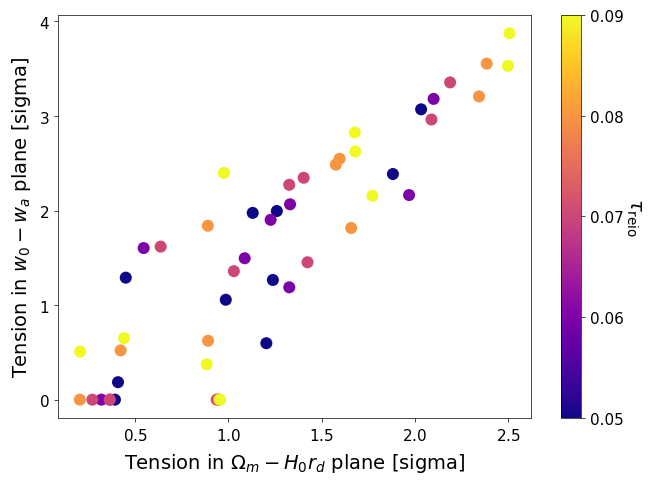

In [ ]:
from getdist import plots
g = plots.get_single_plotter(width_inch=7)
g.settings.scatter_size = 75
g.settings.colormap_scatter = 'plasma'
g.plot_3d(sample,['omh0rd','w0wa','tau'])
plt.savefig('newcorr_1.pdf')

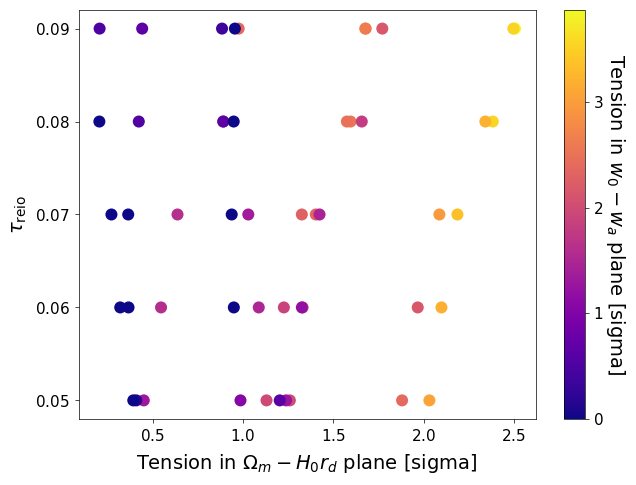

In [ ]:
from getdist import plots
g = plots.get_single_plotter(width_inch=7)
g.settings.scatter_size = 75
g.settings.colormap_scatter = 'plasma'
g.plot_3d(sample,['omh0rd','tau','w0wa'])
plt.savefig('newcorr_2.pdf')

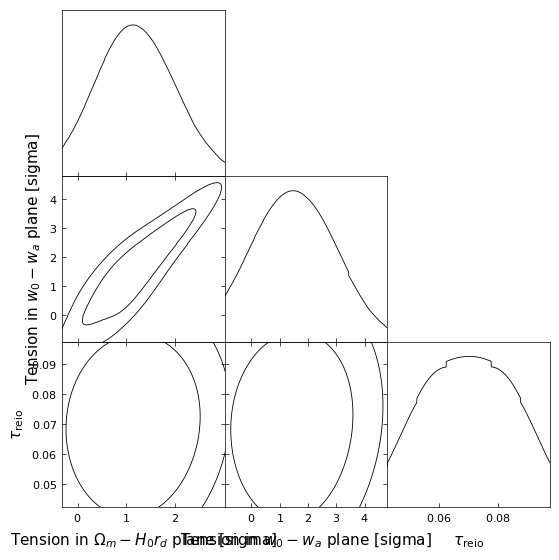

In [ ]:
gdplot = gdplt.get_subplot_plotter(width_inch=6)
gdplot.triangle_plot(sample, names)
plt.savefig('newcorr_3.pdf')